# Introduction to NLP: hands-on examples

This notebook goes with the slides *Introduction to NLP*. Every idea from the slides is tried out on a small **English** and a small **German** example, so you can see where the two languages behave the same and where they do not.

**Tools used**

* [spaCy](https://spacy.io/): tokenization, lemmatization, stop words, part-of-speech tags, dependency parsing, named entities
* [NLTK](https://www.nltk.org/): stemming
* [GloVe](https://nlp.stanford.edu/projects/glove/) (Stanford NLP): pretrained English word vectors, read with numpy
* [VADER](https://github.com/cjhutto/vaderSentiment): sentiment analysis for English
* `re` (standard library): regular expressions

**Contents**

1. Tokens and types
2. Stemming and lemmatization
3. Stop words
4. A small preprocessing pipeline
5. Part-of-speech (POS) tagging
6. Dependency parsing
7. N-grams
8. Word embeddings
9. Named entity recognition
10. Sentiment analysis
11. Regular expressions
12. Exercises

> **Kernel:** run this notebook with the venv kernel you set up in the *14_Using_existing_modules* notebook, so that the libraries below are installed in your venv and not in the system Python.

## 0. Setup

Run the next cell only **once**. It installs the libraries (use `%pip`, so that they land in the environment of the running kernel). If a library was already installed, pip just says so.

In [42]:
%pip install -q spacy nltk vaderSentiment matplotlib pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\klara\Desktop\Programming\piptest\Scripts\python.exe -m pip install --upgrade pip


spaCy needs a *language model* for each language (about 40 MB each). The function below loads a model and downloads it first if it is missing. If the download was necessary and loading still fails, restart the kernel (*Kernel → Restart Kernel...*) and run the cell again.

In [43]:
import spacy
import pandas as pd
from IPython.display import display


def load_model(name):
    # Load a spaCy model; download it first if it is not installed yet.
    try:
        return spacy.load(name)
    except OSError:
        print(f"Downloading {name} (one-time download) ...")
        spacy.cli.download(name)
        return spacy.load(name)


nlp_en = load_model("en_core_web_md")   # English
nlp_de = load_model("de_core_news_md")  # German
print("Models loaded.")

Models loaded.


## 1. Tokens and types

* A **token** is one unit of the text after splitting it: usually a word, but also a number or a punctuation mark.
* A **type** is a *different, unique* word. If the word *smart* occurs twice, it is two tokens but only one type.

Why not simply split at the spaces? Because punctuation then sticks to the words.

In [44]:
text_en = "A smart dog is using a smart phone."
text_de = "Ein kluger Hund benutzt ein Smartphone."

# Naive approach: split at spaces
print(text_en.split())
print(text_de.split())

['A', 'smart', 'dog', 'is', 'using', 'a', 'smart', 'phone.']
['Ein', 'kluger', 'Hund', 'benutzt', 'ein', 'Smartphone.']


Instead, we will use a spaCy's language model to get the tokens.

In [45]:
def get_tokens(nlp, text):
    # the tokens of a text as a list of strings
    tokens = []
    for token in nlp(text):
        tokens.append(token.text)
    return tokens


# The spaCy tokenizer separates the punctuation
print(get_tokens(nlp_en, text_en))
print(get_tokens(nlp_de, text_de))

['A', 'smart', 'dog', 'is', 'using', 'a', 'smart', 'phone', '.']
['Ein', 'kluger', 'Hund', 'benutzt', 'ein', 'Smartphone', '.']


Now we count. Whether punctuation counts as a token is a decision you have to make (and state): we show both numbers. For the types we ignore upper and lower case, so that *A* and *a* are the same type.

In [46]:
def count_tokens_and_types(nlp, text):
    all_tokens = []   # everything, including punctuation
    words = []        # words only
    types = []        # different words, ignoring upper and lower case
    for token in nlp(text):
        all_tokens.append(token.text)
        if not token.is_punct:
            words.append(token.text)
            if token.text.lower() not in types:
                types.append(token.text.lower())
    return len(all_tokens), len(words), sorted(types)

for nlp, text in [(nlp_en, text_en), (nlp_de, text_de)]:
    n_tokens, n_words, types = count_tokens_and_types(nlp, text)
    print(text)
    print(f"  tokens (with punctuation): {n_tokens}")
    print(f"  tokens (words only):       {n_words}")
    print(f"  types:                     {len(types)}  {types}")

A smart dog is using a smart phone.
  tokens (with punctuation): 9
  tokens (words only):       8
  types:                     6  ['a', 'dog', 'is', 'phone', 'smart', 'using']
Ein kluger Hund benutzt ein Smartphone.
  tokens (with punctuation): 7
  tokens (words only):       6
  types:                     5  ['benutzt', 'ein', 'hund', 'kluger', 'smartphone']


### Tricky cases

What counts as "one word" depends on the language and on the tokenizer. Look at what happens to the contraction *wasn't*, to the abbreviation *V.* and to a very long German compound word.

In [47]:
examples = [
    (nlp_en, "Henry V wasn't born in Graz, was he?"),
    (nlp_de, "Heinrich V. wurde nicht in Graz geboren."),
    (nlp_de, "Die Donaudampfschifffahrtsgesellschaft sitzt in Wien."),
]
for nlp, text in examples:
    print(get_tokens(nlp, text))

['Henry', 'V', 'was', "n't", 'born', 'in', 'Graz', ',', 'was', 'he', '?']
['Heinrich', 'V.', 'wurde', 'nicht', 'in', 'Graz', 'geboren', '.']
['Die', 'Donaudampfschifffahrtsgesellschaft', 'sitzt', 'in', 'Wien', '.']


* English *wasn't* becomes two tokens (*was* + *n't*), the German abbreviation *V.* stays one token.
* German compounds are written as one word, so they are one token, however long they are.

## 2. Stemming and lemmatization

Both reduce different forms of a word to a common form, but in different ways:

* **Stemming** cuts off word endings with simple rules. The result is not always a real word (*changing* → *chang*).
* **Lemmatization** looks the word up and returns its dictionary form, the **lemma** (*ran* → *run*). For this it needs to know the part of speech and the context.

### Stemming

We use the Snowball stemmer from NLTK, which exists for both languages.

In [48]:
from nltk.stem import SnowballStemmer

stemmer_en = SnowballStemmer("english")
stemmer_de = SnowballStemmer("german")

words_en = ["changing", "changed", "change", "running", "ran", "runs"]
words_de = ["laufen", "läuft", "lief", "gelaufen", "Kind", "Kinder"]

stems_en = []
for word in words_en:
    stems_en.append(stemmer_en.stem(word))

stems_de = []
for word in words_de:
    stems_de.append(stemmer_de.stem(word))

pd.DataFrame({
    "English word": words_en,
    "English stem": stems_en,
    "German word": words_de,
    "German stem": stems_de,
})

,English word,English stem,German word,German stem
0,changing,chang,laufen,lauf
1,changed,chang,läuft,lauft
2,change,chang,lief,lief
3,running,run,gelaufen,gelauf
4,ran,ran,Kind,kind
5,runs,run,Kinder,kind


The stemmer is fast and works for regular forms (*changing*, *changed*, *change* → *chang*; *Kind*, *Kinder* → *kind*). It fails for **irregular** forms: *ran* stays *ran*, and the German forms of *laufen* end up as four different stems (*lauf*, *lauft*, *lief*, *gelauf*).

### Lemmatization

spaCy lemmatizes while processing the sentence. We put the result in a small table (the number on the left is the position of the token in the sentence).

In [49]:
def analyse(nlp, text):
    # one row per word: token, lemma, part of speech
    rows = []
    for token in nlp(text):
        if not token.is_punct:
            rows.append((token.text, token.lemma_, token.pos_))
    return pd.DataFrame(rows, columns=["token", "lemma", "POS"])

display(analyse(nlp_en, "The children were running through the beautiful gardens."))
display(analyse(nlp_de, "Die Kinder liefen durch die schönen Gärten."))

,token,lemma,POS
0,The,the,DET
1,children,child,NOUN
2,were,be,AUX
3,running,run,VERB
4,through,through,ADP
5,the,the,DET
6,beautiful,beautiful,ADJ
7,gardens,garden,NOUN


,token,lemma,POS
0,Die,der,DET
1,Kinder,Kind,NOUN
2,liefen,laufen,VERB
3,durch,durch,ADP
4,die,der,DET
5,schönen,schön,ADJ
6,Gärten,Garten,NOUN


Note that the lemmatizer also changes words you might not expect: *were* → *be*, *Kinder* → *Kind*, *liefen* → *laufen*, *Gärten* → *Garten* and *die* → *der*. In English, a sentence like *The solar system has eight planets* contains two words whose lemma is a different word form (ignoring capital letters): *has* → *have* and *planets* → *planet*.

In [50]:
display(analyse(nlp_en, "The solar system has eight planets."))
display(analyse(nlp_de, "Das Sonnensystem hat acht Planeten."))

,token,lemma,POS
0,The,the,DET
1,solar,solar,ADJ
2,system,system,NOUN
3,has,have,VERB
4,eight,eight,NUM
5,planets,planet,NOUN


,token,lemma,POS
0,Das,der,DET
1,Sonnensystem,Sonnensystem,NOUN
2,hat,haben,VERB
3,acht,acht,NUM
4,Planeten,Planet,NOUN


### Stemming vs. lemmatization side by side

The same sentences, with the stem and the lemma next to each other. Look at the irregular verbs (*ran*, *lief*, *gelaufen*) and at *is* / *ist*.

In [51]:
def stem_vs_lemma(nlp, stemmer, text):
    rows = []
    for token in nlp(text):
        if not token.is_punct:
            rows.append((token.text, stemmer.stem(token.text), token.lemma_))
    return pd.DataFrame(rows, columns=["token", "stem", "lemma"])

display(stem_vs_lemma(nlp_en, stemmer_en, "She runs every day. Yesterday she ran, and now she is running."))
display(stem_vs_lemma(nlp_de, stemmer_de, "Er läuft jeden Tag. Gestern lief er, und er ist schon wieder gelaufen."))

,token,stem,lemma
0,She,she,she
1,runs,run,run
2,every,everi,every
3,day,day,day
4,Yesterday,yesterday,yesterday
5,she,she,she
6,ran,ran,run
7,and,and,and
8,now,now,now
9,she,she,she


,token,stem,lemma
0,Er,er,er
1,läuft,lauft,laufen
2,jeden,jed,jeder
3,Tag,tag,Tag
4,Gestern,gest,gestern
5,lief,lief,laufen
6,er,er,er
7,und,und,und
8,er,er,er
9,ist,ist,sein


**Rule of thumb:** a stemmer is fast and good enough for simple search tasks; a lemmatizer is slower but gives real words, which matters when you want to read, count or compare the results. German, with its many word forms, benefits especially from lemmatization.

## 3. Stop words

**Stop words** are very frequent words (*the*, *is*, *in*, *and* / *der*, *ist*, *in*, *und*) that carry little meaning on their own. For many tasks they are removed. spaCy keeps a stop word list for each language and marks every token with `is_stop`.

In [52]:
print("English stop words:", len(nlp_en.Defaults.stop_words))
print("German stop words: ", len(nlp_de.Defaults.stop_words))
print(sorted(nlp_en.Defaults.stop_words)[:12])
print(sorted(nlp_de.Defaults.stop_words)[:12])

English stop words: 326
German stop words:  543
["'d", "'ll", "'m", "'re", "'s", "'ve", 'a', 'about', 'above', 'across', 'after', 'afterwards']
['a', 'ab', 'aber', 'ach', 'acht', 'achte', 'achten', 'achter', 'achtes', 'ag', 'alle', 'allein']


In [53]:
def remove_stop_words(nlp, text):
    removed = []
    kept = []
    for token in nlp(text):
        if token.is_stop:
            removed.append(token.text)
        elif not token.is_punct:
            kept.append(token.text)
    return removed, kept


for nlp, text in [
    (nlp_en, "She said that the weather in Graz is usually very nice."),
    (nlp_de, "Sie sagte, dass das Wetter in Graz meistens sehr schön ist."),
]:
    removed, kept = remove_stop_words(nlp, text)
    print(text)
    print("  removed:", removed)
    print("  kept:   ", kept)

She said that the weather in Graz is usually very nice.
  removed: ['She', 'that', 'the', 'in', 'is', 'very']
  kept:    ['said', 'weather', 'Graz', 'usually', 'nice']
Sie sagte, dass das Wetter in Graz meistens sehr schön ist.
  removed: ['Sie', 'sagte', 'dass', 'das', 'in', 'sehr', 'ist']
  kept:    ['Wetter', 'Graz', 'meistens', 'schön']


### Careful: removing stop words can change the meaning

*not* / *nicht* is on the stop word list too. Look at what is left of these sentences.

In [54]:
for nlp, text in [
    (nlp_en, "This movie is not good."),
    (nlp_de, "Dieser Film ist nicht gut."),
]:
    removed, kept = remove_stop_words(nlp, text)
    print(text, "->", kept)

This movie is not good. -> ['movie', 'good']
Dieser Film ist nicht gut. -> ['Film']


After the removal, *This movie is not good* looks like *movie good*, a positive statement. For tasks such as sentiment analysis (see section 10) stop words, and especially negations, should be kept.

## 4. A small preprocessing pipeline

Typical preprocessing combines the steps from above: tokenization → remove punctuation and numbers → remove stop words → lemmatization → lower case. We put them into one function that works for both languages, because the language-specific part is hidden in the model.

In [55]:
def preprocess(nlp, text):
    result = []
    for token in nlp(text):
        if token.is_alpha and not token.is_stop:
            result.append(token.lemma_.lower())
    return result

text_en = "The children were playing in the beautiful gardens, and the weather was nice."
text_de = "Die Kinder spielten in den schönen Gärten, und das Wetter war schön."

print(preprocess(nlp_en, text_en))
print(preprocess(nlp_de, text_de))

['child', 'play', 'beautiful', 'garden', 'weather', 'nice']
['kind', 'spielen', 'schön', 'garten', 'wetter', 'schön']


Two things to notice: both sentences are now reduced to a handful of content words, and the order of operations matters. We lower-case only at the very end, on the lemma. If we lower-cased the text *before* giving it to spaCy, the German model would lose the capital letters that help it to recognize nouns:

In [87]:
def get_lemmas(nlp, text):
    lemmas = []
    for token in nlp(text):
        lemmas.append(token.lemma_)
    return lemmas

print(get_lemmas(nlp_de, "Die Kinder spielten in den schönen Gärten"))
print(get_lemmas(nlp_de, "die kinder spielten in den schönen gärten"))

['der', 'Kind', 'spielen', 'in', 'der', 'schön', 'Garten']
['der', 'Kind', 'spielen', 'in', 'der', 'schön', 'gärten']


With the original spelling *Gärten* becomes *Garten*; written in lower case, *gärten* is no longer recognized as a plural noun and stays unchanged.

## 5. Part-of-speech (POS) tagging

POS tagging assigns a part of speech to every token. spaCy gives two levels:

* `pos_`: a coarse tag that is the same for all languages (the *Universal Dependencies* tag set: `NOUN`, `VERB`, `ADJ`, ...)
* `tag_`: a fine-grained tag that is specific to the model. English models use the *Penn Treebank* tags, the German model the *STTS* tags.

`spacy.explain()` translates a tag into plain words.

In [57]:
def pos_table(nlp, text):
    rows = []
    for token in nlp(text):
        rows.append((token.text, token.pos_, spacy.explain(token.pos_),
                     token.tag_, spacy.explain(token.tag_)))
    return pd.DataFrame(rows, columns=["token", "POS", "meaning", "fine tag", "fine meaning"])

display(pos_table(nlp_en, "A smart dog is using a smart phone."))
display(pos_table(nlp_de, "Ein kluger Hund benutzt ein Smartphone."))

,token,POS,meaning,fine tag,fine meaning
0,A,DET,determiner,DT,determiner
1,smart,ADJ,adjective,JJ,"adjective (English), other noun-modifier (Chin..."
2,dog,NOUN,noun,NN,"noun, singular or mass"
3,is,AUX,auxiliary,VBZ,"verb, 3rd person singular present"
4,using,VERB,verb,VBG,"verb, gerund or present participle"
5,a,DET,determiner,DT,determiner
6,smart,ADJ,adjective,JJ,"adjective (English), other noun-modifier (Chin..."
7,phone,NOUN,noun,NN,"noun, singular or mass"
8,.,PUNCT,punctuation,.,"punctuation mark, sentence closer"


,token,POS,meaning,fine tag,fine meaning
0,Ein,DET,determiner,ART,definite or indefinite article
1,kluger,ADJ,adjective,ADJA,"adjective, attributive"
2,Hund,NOUN,noun,NN,"noun, singular or mass"
3,benutzt,VERB,verb,VVFIN,"finite verb, full"
4,ein,DET,determiner,ART,definite or indefinite article
5,Smartphone,NOUN,noun,NN,"noun, singular or mass"
6,.,PUNCT,punctuation,$.,sentence-final punctuation mark


### The same word, different parts of speech

POS tagging has to look at the context. The English word *book* is a verb in the first sentence and a noun in the second. In German, the capital letter helps: *essen* (verb) and *Essen* (noun).

In [58]:
display(pos_table(nlp_en, "I will book a table. She read the book.")[["token", "POS", "fine tag"]])
display(pos_table(nlp_de, "Wir essen jetzt. Das Essen ist fertig.")[["token", "POS", "fine tag"]])

,token,POS,fine tag
0,I,PRON,PRP
1,will,AUX,MD
2,book,VERB,VB
3,a,DET,DT
4,table,NOUN,NN
5,.,PUNCT,.
6,She,PRON,PRP
7,read,VERB,VBD
8,the,DET,DT
9,book,NOUN,NN


,token,POS,fine tag
0,Wir,PRON,PPER
1,essen,VERB,VVFIN
2,jetzt,ADV,ADV
3,.,PUNCT,$.
4,Das,DET,ART
5,Essen,NOUN,NN
6,ist,AUX,VAFIN
7,fertig,ADV,ADJD
8,.,PUNCT,$.


## 6. Dependency parsing

A dependency parser finds how the words of a sentence are connected. Every word depends on one other word, its **head**; the main verb is the **root** of the sentence. The label of the connection (`dep_`) names the relation, for example *subject* or *object*.

The English model uses the *ClearNLP* labels (`nsubj`, `dobj`, ...), the German model the *TIGER* labels (`sb` = subject, `oa` = accusative object, `nk` = noun kernel element).

In [59]:
def dep_table(nlp, text):
    rows = []
    for token in nlp(text):
        rows.append((token.text, token.dep_, spacy.explain(token.dep_), token.head.text))
    return pd.DataFrame(rows, columns=["token", "relation", "meaning", "head"])

display(dep_table(nlp_en, "A smart dog is using a smart phone."))
display(dep_table(nlp_de, "Ein kluger Hund benutzt ein Smartphone."))

,token,relation,meaning,head
0,A,det,determiner,dog
1,smart,amod,adjectival modifier,dog
2,dog,nsubj,nominal subject,using
3,is,aux,auxiliary,using
4,using,ROOT,root,using
5,a,det,determiner,phone
6,smart,amod,adjectival modifier,phone
7,phone,dobj,direct object,using
8,.,punct,punctuation,using


,token,relation,meaning,head
0,Ein,nk,noun kernel element,Hund
1,kluger,nk,noun kernel element,Hund
2,Hund,sb,subject,benutzt
3,benutzt,ROOT,root,benutzt
4,ein,nk,noun kernel element,Smartphone
5,Smartphone,oa,accusative object,benutzt
6,.,punct,punctuation,benutzt


The table is easier to read as a picture. spaCy's visualizer `displacy` draws the arrows from the head to the dependent word.

In [60]:
from spacy import displacy

options = {"compact": True, "distance": 100}
displacy.render(nlp_en("The dog slept."), style="dep", jupyter=True, options=options)
displacy.render(nlp_de("Der Hund schlief."), style="dep", jupyter=True, options=options)

In both languages the verb *slept* / *schlief* is the root (the root has no arrow pointing to it) and *dog* / *Hund* is its subject.

## 7. N-grams

An **n-gram** is a sequence of *n* neighbouring tokens: 2 tokens = bigram, 3 tokens = trigram. N-grams keep a little bit of the word order, which a simple list of words loses.

In [61]:
def get_words(nlp, text):
    # the tokens of a text without punctuation
    words = []
    for token in nlp(text):
        if not token.is_punct:
            words.append(token.text)
    return words

def make_ngrams(tokens, n):
    result = []
    for i in range(len(tokens) - n + 1):
        result.append(" ".join(tokens[i:i + n]))   # n neighbouring tokens, joined by spaces
    return result

tokens_en = get_words(nlp_en, "The solar system has eight planets.")
tokens_de = get_words(nlp_de, "Das Sonnensystem hat acht Planeten.")

for tokens in (tokens_en, tokens_de):
    print(tokens)
    print("  bigrams: ", make_ngrams(tokens, 2))
    print("  trigrams:", make_ngrams(tokens, 3))

['The', 'solar', 'system', 'has', 'eight', 'planets']
  bigrams:  ['The solar', 'solar system', 'system has', 'has eight', 'eight planets']
  trigrams: ['The solar system', 'solar system has', 'system has eight', 'has eight planets']
['Das', 'Sonnensystem', 'hat', 'acht', 'Planeten']
  bigrams:  ['Das Sonnensystem', 'Sonnensystem hat', 'hat acht', 'acht Planeten']
  trigrams: ['Das Sonnensystem hat', 'Sonnensystem hat acht', 'hat acht Planeten']


NLTK has a ready-made function for this; it returns tuples instead of list of strings.

In [62]:
from nltk.util import ngrams

print(list(ngrams(tokens_en, 2)))

[('The', 'solar'), ('solar', 'system'), ('system', 'has'), ('has', 'eight'), ('eight', 'planets')]


### What are n-grams good for? Predicting the next word

If we count which word follows which, we get a tiny language model: for a given word we can say which word is most likely to come next.

In [63]:
from collections import Counter, defaultdict

corpus = "The cat sat on the mat. The cat ate the fish. The dog sat on the mat."
tokens = []
for token in nlp_en(corpus):
    tokens.append(token.lower_)

followers = defaultdict(Counter)
for first, second in zip(tokens, tokens[1:]):
    followers[first][second] += 1

print("After 'the':", followers["the"].most_common())
print("After 'sat':", followers["sat"].most_common())
print("After 'cat':", followers["cat"].most_common())

After 'the': [('cat', 2), ('mat', 2), ('fish', 1), ('dog', 1)]
After 'sat': [('on', 2)]
After 'cat': [('sat', 1), ('ate', 1)]


After *the* the next word could be *cat* or *mat* (both twice). Real language models work on the same principle, but with much more text and much longer contexts.

## 8. Word embeddings

An **embedding** represents a word as a vector, a list of numbers. Words that are used in similar contexts get similar vectors, so *cat* ends up close to *dog* and far from *car*.

For English we load pretrained **GloVe** vectors (400,000 words, 50 numbers per word, about 66 MB). They were trained at Stanford on Wikipedia and news texts. The file is downloaded once into the folder of this notebook and read with numpy, so no extra library is needed.

In [64]:
import gzip
import os
import urllib.request

import numpy as np

# The file is stored on GitHub by the gensim-data project (we only use the file, not the gensim library)
GLOVE_URL = "https://github.com/RaRe-Technologies/gensim-data/releases/download/glove-wiki-gigaword-50/glove-wiki-gigaword-50.gz"
GLOVE_FILE = "glove-wiki-gigaword-50.gz"

if not os.path.exists(GLOVE_FILE):
    print("Downloading GloVe vectors (66 MB, one-time download) ...")
    urllib.request.urlretrieve(GLOVE_URL, GLOVE_FILE + ".part")
    os.replace(GLOVE_FILE + ".part", GLOVE_FILE)

glove_words = []
glove_vectors = []
with gzip.open(GLOVE_FILE, "rt", encoding="utf8") as f:
    next(f)                                    # first line: number of words and dimensions
    for line in f:
        parts = line.rstrip().split(" ")
        glove_words.append(parts[0])           # the word ...
        glove_vectors.append(np.array(parts[1:], dtype=np.float32))   # ... and its 50 numbers

glove_vectors = np.vstack(glove_vectors)
glove_index = {}                                                     # word -> row number
for i in range(len(glove_words)):
    glove_index[glove_words[i]] = i
print(glove_vectors.shape)

(400000, 50)


Three small helper functions: `vec` gives the vector of a word, `similarity` compares two words and `most_similar` finds the nearest words (it can also add and subtract words, see below).

In [65]:
def vec(word):
    return glove_vectors[glove_index[word]]

# Scale every vector to length 1: then a dot product is the cosine similarity
glove_unit = glove_vectors / np.linalg.norm(glove_vectors, axis=1, keepdims=True)

def similarity(word1, word2):
    return float(glove_unit[glove_index[word1]] @ glove_unit[glove_index[word2]])

def most_similar(positive, negative=(), topn=5):
    if isinstance(positive, str):
        positive = [positive]
    query = np.zeros(glove_unit.shape[1])
    for w in positive:
        query = query + glove_unit[glove_index[w]]
    for w in negative:
        query = query - glove_unit[glove_index[w]]
    scores = glove_unit @ (query / np.linalg.norm(query))
    result = []
    for i in np.argsort(-scores):
        word = glove_words[i]
        if word not in positive and word not in negative:   # do not return the question words
            result.append((word, round(float(scores[i]), 2)))
        if len(result) == topn:
            break
    return result

print(vec("cat").shape)
print(vec("cat")[:10].round(3))

(50,)
[ 0.453 -0.501 -0.537 -0.016  0.222  0.546 -0.673 -0.689  0.635 -0.197]


The word *cat* is a list of 50 numbers; the numbers alone mean nothing to us, but we can compare them. The **cosine similarity** is 1 for vectors pointing in the same direction and close to 0 for unrelated ones.

In [66]:
pairs = [("cat", "dog"), ("cat", "car"), ("king", "queen"), ("man", "woman"), ("king", "banana")]
rows = []
for a, b in pairs:
    rows.append((a, b, round(similarity(a, b), 2)))
pd.DataFrame(rows, columns=["word 1", "word 2", "similarity"])

,word 1,word 2,similarity
0,cat,dog,0.92
1,cat,car,0.36
2,king,queen,0.78
3,man,woman,0.89
4,king,banana,0.22


In [67]:
print(most_similar("cat", topn=5))

[('dog', 0.92), ('rabbit', 0.85), ('monkey', 0.8), ('rat', 0.79), ('cats', 0.79)]


### Calculating with meaning

Differences between vectors capture relations. If we take the vector of *king*, subtract *man* and add *woman*, we arrive near *queen*. The same works for countries and capitals (*paris* − *france* + *italy* ≈ *rome*).

In [68]:
print(most_similar(positive=["king", "woman"], negative=["man"], topn=3))
print(most_similar(positive=["paris", "italy"], negative=["france"], topn=3))

[('queen', 0.85), ('throne', 0.77), ('prince', 0.76)]
[('rome', 0.85), ('milan', 0.78), ('turin', 0.77)]


The vectors have 50 dimensions, which we cannot draw. A simple projection to 2 dimensions (PCA, computed here with numpy) keeps the most important differences. The arrows connect male and female words: they point in roughly the same direction, which is exactly the "gender" relation the vectors have learned.

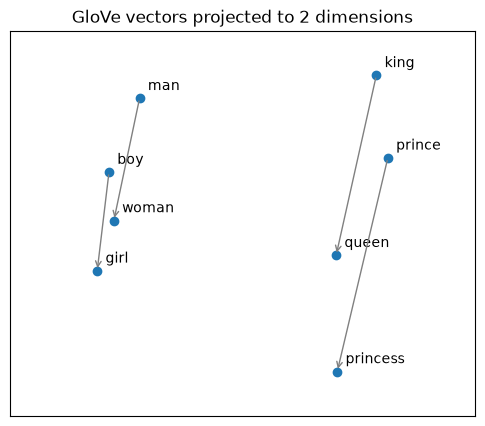

In [69]:
import matplotlib.pyplot as plt

demo_words = ["man", "woman", "boy", "girl", "king", "queen", "prince", "princess"]
demo_vectors = []
for w in demo_words:
    demo_vectors.append(vec(w))
X = np.array(demo_vectors)
X = X - X.mean(axis=0)
_, _, Vt = np.linalg.svd(X, full_matrices=False)
coords = dict(zip(demo_words, X @ Vt[:2].T))   # first two principal components

fig, ax = plt.subplots(figsize=(6, 5))
for w, (x, y) in coords.items():
    ax.scatter(x, y, color="tab:blue")
    ax.annotate(w, (x, y), textcoords="offset points", xytext=(6, 6))
for male, female in [("man", "woman"), ("boy", "girl"), ("king", "queen"), ("prince", "princess")]:
    ax.annotate("", xy=coords[female], xytext=coords[male],
                arrowprops=dict(arrowstyle="->", color="gray"))
ax.margins(x=0.3, y=0.15)
ax.set_title("GloVe vectors projected to 2 dimensions")
ax.set_xticks([])
ax.set_yticks([])
plt.show()

### German

The medium German spaCy model also contains word vectors. We use them for a quick similarity check.

In [70]:
pairs_de = [("Katze", "Hund"), ("Katze", "Auto"), ("König", "Königin"), ("Haus", "Gebäude"), ("König", "Banane")]
rows = []
for a, b in pairs_de:
    rows.append((a, b, round(nlp_de(a)[0].similarity(nlp_de(b)[0]), 2)))
pd.DataFrame(rows, columns=["word 1", "word 2", "similarity"])

,word 1,word 2,similarity
0,Katze,Hund,0.68
1,Katze,Auto,0.23
2,König,Königin,0.77
3,Haus,Gebäude,0.61
4,König,Banane,-0.05


The pattern is the same: related words get high values, unrelated words low values.

**A note on the spaCy models:** the medium models keep only a reduced table of vectors that is shared between similar words. That is fine for a rough demo like the one above, but it can give misleading results (the medium *English* model, for example, rates *cat* and *dog* as identical). This is why we used GloVe for the English examples. For serious work use the large models (`en_core_web_lg`, `de_core_news_lg`) or dedicated vectors such as fastText.

## 9. Named entity recognition (NER)

NER finds real-world names in a text (persons, places, organizations, dates...) and gives each one a label. The label sets differ between the models: the English model knows `PERSON`, `GPE` (countries, cities), `ORG`, `DATE`, ..., the German model `PER`, `LOC`, `ORG`, `MISC`.

In [71]:
def entities(nlp, text):
    result = []
    for ent in nlp(text).ents:
        result.append((ent.text, ent.label_, spacy.explain(ent.label_)))
    return result

for nlp, text in [
    (nlp_en, "Claude Monet was born in Paris."),
    (nlp_de, "Claude Monet wurde in Paris geboren."),
]:
    print(text)
    for entity in entities(nlp, text):
        print("   ", entity)

Claude Monet was born in Paris.
    ('Claude Monet', 'PERSON', 'People, including fictional')
    ('Paris', 'GPE', 'Countries, cities, states')
Claude Monet wurde in Paris geboren.
    ('Claude Monet', 'PER', 'Named person or family.')
    ('Paris', 'LOC', 'Non-GPE locations, mountain ranges, bodies of water')


`displacy` can also highlight the entities directly in the text.

In [88]:
displacy.render(nlp_en("Claude Monet was born in Paris."), style="ent", jupyter=True)
displacy.render(nlp_de("Claude Monet wurde in Paris geboren."), style="ent", jupyter=True)

NER models can make mistakes, and they are only as good as the data they were trained on. Always check the output before you trust it.

## 10. Sentiment analysis

Sentiment analysis decides whether a text is positive, negative or neutral. **VADER** is a rule-based tool: it has a dictionary of words with sentiment scores and a few rules (for example for negation). The `compound` value goes from −1 (very negative) to +1 (very positive).

In [73]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

vader = SentimentIntensityAnalyzer()

for text in [
    "Our stay at the hotel was really good.",
    "This product was so bad that I will never buy it again.",
    "This movie is not good.",
]:
    print(f"{vader.polarity_scores(text)['compound']:+.2f}  {text}")

+0.49  Our stay at the hotel was really good.
-0.67  This product was so bad that I will never buy it again.
-0.34  This movie is not good.


VADER handles the negation in *This movie is not good* correctly (negative score), which is exactly what we would lose by removing stop words (section 3).

### A tool for one language does not work for another

VADER is built for **English**. What happens if we give it German sentences, one positive and one negative?

In [74]:
for text in [
    "Unser Aufenthalt im Hotel war wirklich gut.",
    "Das Produkt war so schlecht, dass ich es nie wieder kaufen werde.",
]:
    print(f"{vader.polarity_scores(text)['compound']:+.2f}  {text}")

-0.60  Unser Aufenthalt im Hotel war wirklich gut.
-0.60  Das Produkt war so schlecht, dass ich es nie wieder kaufen werde.


Both sentences get the same negative score, although the first one is positive. The tool does not warn us, it just gives a number. This is a general lesson: **always check that a tool was made for the language of your data.**

For German we need a German resource. To see the principle, here is a deliberately tiny **toy** version of a lexicon-based analyzer with a handful of words and one negation rule. It is only an illustration, not a usable tool (real systems use large lexicons or trained models).

In [75]:
lexicon_de = {"gut": 1, "toll": 2, "super": 2, "schön": 1,
              "schlecht": -2, "schlimm": -2, "furchtbar": -3}
negations_de = {"nicht", "kein", "nie"}

def toy_sentiment_de(text):
    score = 0
    previous = ""
    for token in nlp_de(text):
        value = lexicon_de.get(token.lemma_.lower(), 0)
        if value and previous in negations_de:
            value = -value            # "nicht gut" -> negative
        score += value
        previous = token.lower_
    return score

for text in [
    "Unser Aufenthalt im Hotel war wirklich gut.",
    "Das Produkt war so schlecht, dass ich es nie wieder kaufen werde.",
    "Der Film war nicht gut.",
]:
    print(f"{toy_sentiment_de(text):+d}  {text}")

+1  Unser Aufenthalt im Hotel war wirklich gut.
-2  Das Produkt war so schlecht, dass ich es nie wieder kaufen werde.
-1  Der Film war nicht gut.


The toy analyzer gets these three sentences right, but it would fail on most others (*Das Essen war ein Albtraum*, irony, words that are not in the lexicon...). Building and testing a good analyzer is a real piece of work.

## 11. Regular expressions

A **regular expression** (regex) describes a *pattern* of characters. It does not know any language, which makes it useful for things with a fixed form: hashtags, phone numbers, dates, e-mail addresses. In Python we use the module `re`.

| Pattern | Meaning |
|---|---|
| `.` | any one character (wildcard) |
| `?`, `*`, `+` | the previous character 0 or 1 times, 0 or more times, 1 or more times |
| `{3}` | exactly 3 times |
| `[aeiou]` | one character out of the set |
| `[^aeiou]` | one character *not* in the set |
| `\d`, `\w`, `\s` | a digit, a "word character" (letter, digit, `_`), a whitespace character |
| `\b` | a word boundary |
| `^`, `$` | start / end of the text |

`re.findall(pattern, text)` returns all matches, `re.sub(pattern, replacement, text)` replaces them.

In [76]:
import re

# wildcard: c + any character + t
print(re.findall(r"c.t", "cat cot cut cart ct"))

# '?': the 'o' is optional
print(re.findall(r"ho?", "h ho hoo"))

# character classes
print(re.findall(r"[aeiou]", "natural language processing"))
print(re.findall(r"[^aeiou\s]", "NLP is fun"))

['cat', 'cot', 'cut']
['h', 'ho', 'ho']
['a', 'u', 'a', 'a', 'u', 'a', 'e', 'o', 'e', 'i']
['N', 'L', 'P', 's', 'f', 'n']


Notice that `ho?` finds *h*, *ho* and only the first *ho* of *hoo*, and that `[^aeiou]` means "any character except a vowel", which includes digits, spaces and punctuation, not only consonants (that is why we also excluded `\s` in the last example).

### Patterns for real data

Hashtags, phone numbers and dates have a fixed form. `\w` also matches letters with umlauts in Python 3, so the same patterns work for German.

In [77]:
text = "Loved the show! #bestsingerever #music Wunderschöner Abend #schönerTag"
print(re.findall(r"#\w+", text))

contact = "Call us: +43 316 380 123 or write to office@example.org"
print(re.findall(r"\+?\d[\d ]{7,}\d", contact))          # phone number
print(re.findall(r"[\w.]+@[\w.]+\.\w+", contact))        # e-mail address

# Anonymize: hide the last three digits of the phone number
print(re.sub(r"\d{3}$", "XXX", "+43 316 380 123"))

# dates like 9.7.2024 or 09.07.2024
print(re.findall(r"\b\d{1,2}\.\d{1,2}\.\d{4}\b", "The course starts on 9.7.2024 and ends on 19.7.2024."))

['#bestsingerever', '#music', '#schönerTag']
['+43 316 380 123']
['office@example.org']
+43 316 380 XXX
['9.7.2024', '19.7.2024']


### Regex as a mini-tokenizer

With `\w+` we can split a text into words. But a regex has no knowledge of the language, so it cannot handle *wasn't* as well as the spaCy tokenizer from section 1.

In [78]:
text = "Henry V wasn't born in Graz."
print(re.findall(r"\w+", text))                   # regex: words only, splits wasn't into 'wasn' and 't'
print(get_tokens(nlp_en, text))                   # spaCy: knows about contractions

['Henry', 'V', 'wasn', 't', 'born', 'in', 'Graz']
['Henry', 'V', 'was', "n't", 'born', 'in', 'Graz', '.']


## 12. Exercises

Use the cells below. For each task try an English **and** a German sentence, and compare the results.

1. Lemmatize your own sentence in each language. Which tokens change? Are there mistakes?
2. Write a function `content_words(nlp, text)` that returns only the nouns, verbs and adjectives of a text (use `token.pos_`).
3. Compute all trigrams of a text with 20 or more words and find the most frequent one.
4. Find the five words most similar to *queen* and to *berlin* in the GloVe vectors. Does anything surprise you?
5. Write a regex that finds all years between 1900 and 2099 in a text.
6. Run `displacy` with `style="ent"` on a news sentence from your own language. How many entities does the model find, and how many are correct?

In [80]:
# Exercise 1

In [81]:
# Exercise 2

In [82]:
# Exercise 3

In [83]:
# Exercise 4

In [84]:
# Exercise 5

In [85]:
# Exercise 6

## Licence

This notebook was created by Klara Venglarova, supported by Claude.ai. It is not intended as an independent material but rather as an enrichment to the NLP_Intro presentation.